<a href="https://colab.research.google.com/github/nourMelegy/City-Hotel-Booking-Demand-ML-Model/blob/clustering/clustering_initial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("/content/clustering_X.csv")
display(df.head())
print("shape:", df.shape)
print(df.describe())
print(df.dtypes)


,LeadTime_log,TotalNights_log,TotalGuests,HasKids,ADR_capped,IsRepeatedGuest,HasAgent,MarketSegment_Aviation,MarketSegment_Complementary,MarketSegment_Corporate,...,DepositType_Non Refund,DepositType_Refundable,CustomerType_Contract,CustomerType_Group,CustomerType_Transient,CustomerType_Transient-Party,Meal_BB,Meal_FB,Meal_HB,Meal_SC
0,-1.348016,-0.518454,-1.509126,-0.270758,-2.742315,-0.15418,0.335958,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.338759,0.785069,0.075897,-0.270758,-0.758828,-0.15418,0.335958,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2,0.140423,0.785069,-1.509126,-0.270758,-0.979216,-0.15418,0.335958,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,0.367923,1.643678,0.075897,-0.270758,-0.758828,-0.15418,0.335958,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0.422665,-0.518454,0.075897,-0.270758,-0.758828,-0.15418,0.335958,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


shape: (78899, 26)
       LeadTime_log  TotalNights_log   TotalGuests       HasKids  \
count  7.889900e+04     7.889900e+04  7.889900e+04  7.889900e+04   
mean   3.371744e-16    -4.755023e-17  6.051848e-17  8.645496e-17   
std    1.000006e+00     1.000006e+00  1.000006e+00  1.000006e+00   
min   -2.638881e+00    -1.553119e+00 -1.509126e+00 -2.707577e-01   
25%   -5.306457e-01    -5.184541e-01  7.589727e-02 -2.707577e-01   
50%    2.252242e-01     2.156523e-01  7.589727e-02 -2.707577e-01   
75%    7.482655e-01     7.850694e-01  7.589727e-02 -2.707577e-01   
max    1.637036e+00     6.609247e+00  1.592613e+01  3.693339e+00   

         ADR_capped  IsRepeatedGuest      HasAgent  MarketSegment_Aviation  \
count  7.889900e+04     7.889900e+04  7.889900e+04            78899.000000   
mean  -7.492764e-17     1.037460e-16 -2.276647e-16                0.002928   
std    1.000006e+00     1.000006e+00  1.000006e+00                0.054030   
min   -2.742315e+00    -1.541802e-01 -2.976560e+00      

In [2]:
print(df.dtypes)

LeadTime_log                    float64
TotalNights_log                 float64
TotalGuests                     float64
HasKids                         float64
ADR_capped                      float64
IsRepeatedGuest                 float64
HasAgent                        float64
MarketSegment_Aviation          float64
MarketSegment_Complementary     float64
MarketSegment_Corporate         float64
MarketSegment_Direct            float64
MarketSegment_Groups            float64
MarketSegment_Offline TA/TO     float64
MarketSegment_Online TA         float64
MarketSegment_Undefined         float64
DepositType_No Deposit          float64
DepositType_Non Refund          float64
DepositType_Refundable          float64
CustomerType_Contract           float64
CustomerType_Group              float64
CustomerType_Transient          float64
CustomerType_Transient-Party    float64
Meal_BB                         float64
Meal_FB                         float64
Meal_HB                         float64


In [5]:
df_raw=df.copy()

In [6]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

num_cols = ["LeadTime_log", "TotalNights_log", "TotalGuests", "ADR_capped"]
bin_cols = ["HasKids", "IsRepeatedGuest", "HasAgent"]
dummy_cols = [c for c in df_raw.columns if c.startswith(("MarketSegment_", "DepositType_", "CustomerType_", "Meal_"))]

df_raw["TotalGuests"] = df_raw["TotalGuests"].clip(upper=df_raw["TotalGuests"].quantile(0.995))
df_raw["TotalNights_log"] = df_raw["TotalNights_log"].clip(upper=df_raw["TotalNights_log"].quantile(0.995))

W = 0.5  # try 0.3, 0.5, 1.0
X = np.hstack([
    StandardScaler().fit_transform(df_raw[num_cols]),
    df_raw[bin_cols].values * W,
    df_raw[dummy_cols].values * W,
])

idx = np.random.RandomState(0).choice(len(X), 10000, replace=False)
for k in range(2, 11):
    km = KMeans(k, n_init=10, random_state=0).fit(X)
    print(k, round(km.inertia_),
          round(silhouette_score(X[idx], km.labels_[idx]), 3),
          round(davies_bouldin_score(X, km.labels_), 3))

2 334885 0.234 1.812
3 270893 0.269 1.518
4 240479 0.169 1.603
5 221743 0.181 1.475
6 206729 0.18 1.473
7 191510 0.19 1.438
8 182484 0.172 1.456
9 174416 0.177 1.438
10 167293 0.174 1.48


I will try the remaining weights in phase 2 and see which produces the best silhoute scores


In [7]:
k = 3
km = KMeans(k, n_init=20, random_state=0).fit(X)
df_raw["cluster"] = km.labels_
print(df_raw["cluster"].value_counts(normalize=True))
from sklearn.metrics import adjusted_rand_score
labels = [KMeans(k, n_init=10, random_state=s).fit_predict(X) for s in range(5)]
print([round(adjusted_rand_score(labels[0], l), 3) for l in labels[1:]])

cluster
2    0.646941
1    0.225098
0    0.127961
Name: proportion, dtype: float64
[1.0, 1.0, 1.0, 0.999]


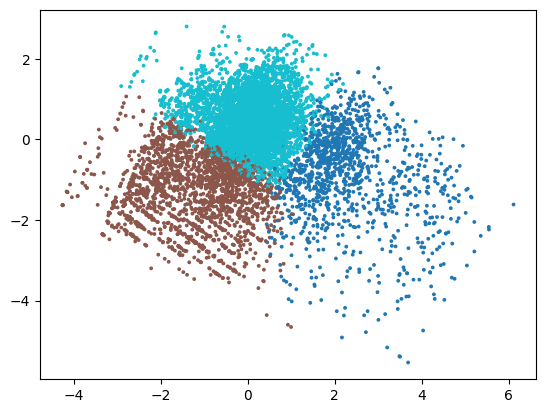

In [8]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

Z = PCA(n_components=2).fit_transform(X)
plt.scatter(Z[idx,0], Z[idx,1], c=df_raw["cluster"].values[idx], s=3, cmap="tab10")

 0     14604
 2     13542
 3     11382
-1      8142
 6      3020
       ...  
 36       20
 41       20
 91       20
 98       20
 70       19
Name: count, Length: 129, dtype: int64


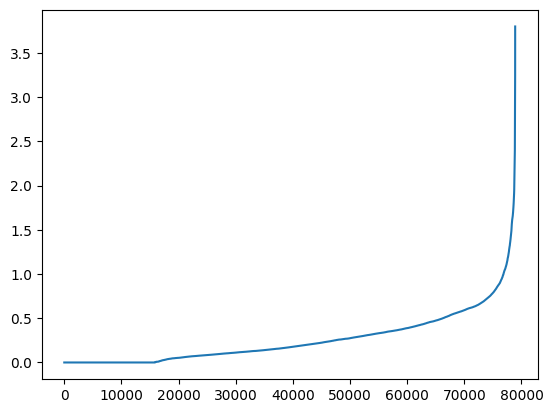

In [16]:
from sklearn.neighbors import NearestNeighbors
Zp = PCA(n_components=10).fit_transform(X)
d = np.sort(NearestNeighbors(n_neighbors=20).fit(Zp).kneighbors(Zp)[0][:,-1])
plt.plot(d)

from sklearn.cluster import DBSCAN, HDBSCAN
db = DBSCAN(eps=0.5, min_samples=20).fit(Zp)
print(pd.Series(db.labels_).value_counts())

In [15]:
profile = df_raw.groupby("cluster").agg(
    size=("cluster", "size"),
    guests=("TotalGuests", "mean"),
    kids=("HasKids", "mean"),
    repeat=("IsRepeatedGuest", "mean"),
)
print(profile.round(2))

ms_cols = [c for c in df_raw.columns if c.startswith("MarketSegment_")]
ms_profile = df_raw.groupby("cluster")[ms_cols].mean().round(2)
display(ms_profile)

          size  guests  kids  repeat
cluster                             
0        10096    1.81  1.65   -0.14
1        17760   -0.65 -0.23    0.44
2        51043   -0.14 -0.25   -0.12


,MarketSegment_Aviation,MarketSegment_Complementary,MarketSegment_Corporate,MarketSegment_Direct,MarketSegment_Groups,MarketSegment_Offline TA/TO,MarketSegment_Online TA,MarketSegment_Undefined
cluster,,,,,,,,
0,0.00,0.00,0.00,0.11,0.01,0.06,0.81,0.0
1,0.01,0.03,0.15,0.15,0.07,0.14,0.46,0.0
2,0.00,0.00,0.01,0.04,0.25,0.27,0.44,0.0


In [17]:
from sklearn.metrics import silhouette_score, davies_bouldin_score
import pandas as pd
import numpy as np

X_sample = X[idx]
Zp_sample = Zp[idx]

kmeans_full_labels = km.labels_[idx]

# Train KMeans on the PCA space (Zp) using same k=3 for comparison
from sklearn.cluster import KMeans
km_pca_model = KMeans(n_clusters=3, n_init=20, random_state=0).fit(Zp)
kmeans_pca_labels = km_pca_model.labels_[idx]

db_labels = db.labels_[idx]

results = []

sil_full = silhouette_score(X_sample, kmeans_full_labels)
db_full = davies_bouldin_score(X_sample, kmeans_full_labels)
results.append({
    "Model": "KMeans (Full Space)",
    "Dimensions": X.shape[1],
    "Silhouette Score": sil_full,
    "Davies-Bouldin Index": db_full
})

# 2. Evaluate K-Means on PCA Space
sil_pca = silhouette_score(Zp_sample, kmeans_pca_labels)
db_pca_val = davies_bouldin_score(Zp_sample, kmeans_pca_labels)
results.append({
    "Model": "KMeans (PCA Space)",
    "Dimensions": Zp.shape[1],
    "Silhouette Score": sil_pca,
    "Davies-Bouldin Index": db_pca_val
})

unique_db_labels = np.unique(db_labels)
if len(unique_db_labels) > 1 and not (len(unique_db_labels) == 2 and -1 in unique_db_labels):
    # We calculate metrics excluding noise points for DBSCAN to make it a fair comparison of cohesive groups
    non_noise_mask = db_labels != -1
    if np.sum(non_noise_mask) > 10:
        sil_db = silhouette_score(Zp_sample[non_noise_mask], db_labels[non_noise_mask])
        db_db = davies_bouldin_score(Zp_sample[non_noise_mask], db_labels[non_noise_mask])
    else:
        sil_db, db_db = np.nan, np.nan
else:
    sil_db, db_db = np.nan, np.nan

results.append({
    "Model": "DBSCAN (PCA Space - Excl. Noise)",
    "Dimensions": Zp.shape[1],
    "Silhouette Score": sil_db,
    "Davies-Bouldin Index": db_db
})

# Display summary comparison table
df_comparison = pd.DataFrame(results)
display(df_comparison.round(4))

,Model,Dimensions,Silhouette Score,Davies-Bouldin Index
0,KMeans (Full Space),26,0.2688,1.5296
1,KMeans (PCA Space),10,0.2771,1.4976
2,DBSCAN (PCA Space - Excl. Noise),10,-0.0586,1.1325


In [18]:
labels_db = db.labels_
n_clusters = len(set(labels_db)) - (1 if -1 in labels_db else 0)
print("clusters:", n_clusters, "| noise %:", round((labels_db == -1).mean() * 100, 1))
print(pd.Series(labels_db[labels_db != -1]).value_counts().head(10))

clusters: 128 | noise %: 10.3
0     14604
2     13542
3     11382
6      3020
26     2503
7      2331
4      2031
5      1774
21     1766
40     1423
Name: count, dtype: int64
